# t-SNE による可視化 — PCA で前処理してから掛ける

**出典**　機械学習 4 分野の教科書 — 第 10 章 3-B 次元削減と異常検知 ／ 07 実装：圧縮して、見て、異常を見つける

**このノートのパス**　`ml-code/10_dimreduction_anomaly/02_tsne.ipynb`

**このノートで確かめること**
**t-SNE の前に PCA で 50 次元に落とす**のが定石。速度と安定性の両方が上がる。
そして**t-SNE の軸に意味は無く、クラスタ間の距離も信用できない**ことを確かめる。

| 項目 | 内容 |
|---|---|
| 必要なパッケージ | `scikit-learn numpy matplotlib` |
| 実行時間の目安 | 約 1 分 |
| 前提 | **このノート単体で完結する**（他のノートを先に実行する必要はない） |

In [2]:
# 未導入なら実行する（Colab など）
# !pip install -q scikit-learn numpy matplotlib

  File "<local-python>/lib/python3.10/site-packages/joblib/externals/loky/backend/context.py", line 264, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_darwin()
  File "<local-python>/lib/python3.10/site-packages/joblib/externals/loky/backend/context.py", line 420, in _count_physical_cores_darwin
    return int(cpu_info)


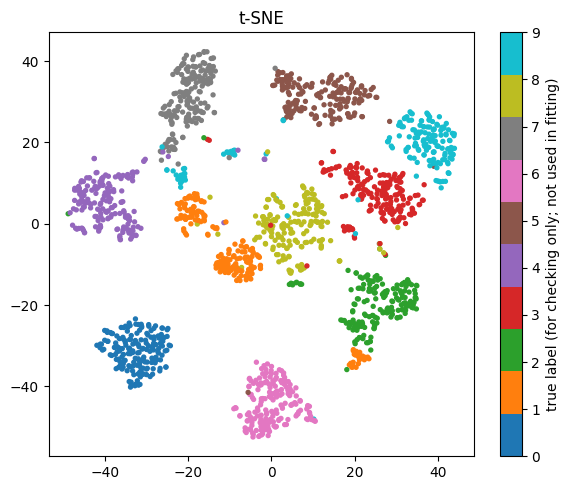

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

RS = 42
X, y = load_digits(return_X_y=True)
Xs = StandardScaler().fit_transform(X)

X_pca50 = PCA(n_components=50, random_state=RS).fit_transform(Xs)

emb = TSNE(n_components=2, perplexity=30, init="pca",
           learning_rate="auto", random_state=RS).fit_transform(X_pca50)

plt.figure(figsize=(6, 5))
sc = plt.scatter(emb[:, 0], emb[:, 1], c=y, s=8, cmap="tab10")
plt.colorbar(sc, label="true label (for checking only; not used in fitting)")
plt.title("t-SNE"); plt.tight_layout(); plt.show()

### perplexity を変えると絵が変わる — 「見えた構造」を鵜呑みにしないための確認

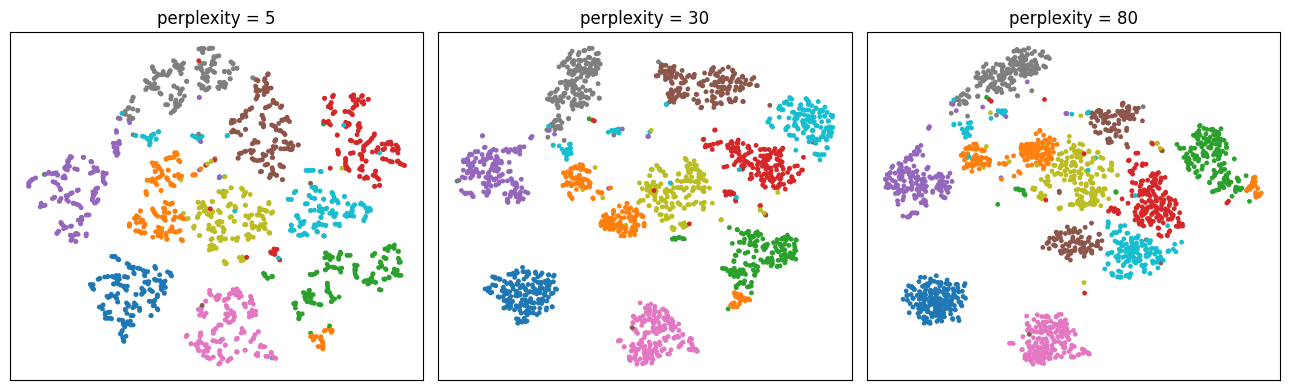

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, perp in zip(axes, [5, 30, 80]):
    e = TSNE(n_components=2, perplexity=perp, init="pca",
             learning_rate="auto", random_state=RS).fit_transform(X_pca50)
    ax.scatter(e[:, 0], e[:, 1], c=y, s=6, cmap="tab10")
    ax.set_title(f"perplexity = {perp}"); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

## 読み取りどころ

- **t-SNE の前に PCA で 50 次元に落とすのが定石。**計算量が大きく下がり、高次元のノイズに引きずられにくくなる。
- **`init="pca"` は再現性のために重要。**既定のランダム初期化では実行ごとに絵が変わる。
- ⚠️ **軸に意味は無い。**「横軸が大きいほど〜」という読み方は成立しない。
- ⚠️ **クラスタ間の距離も信用できない。**t-SNE は近傍関係を保つことを目的にしており、離れたかたまり同士の距離は保存されない。**「A と B は近く、C は遠い」と言ってはいけない。**
- ⚠️ **`perplexity` で絵が変わる。**上のセルで確認できるとおり、小さいと細かく割れ、大きいとまとまる。**1 枚だけ見て構造を語らないこと。**

t-SNE は**仮説を作る道具**であって、**仮説を検証する道具ではない**。